In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [3]:
dataset, variances = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


In [265]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [266]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

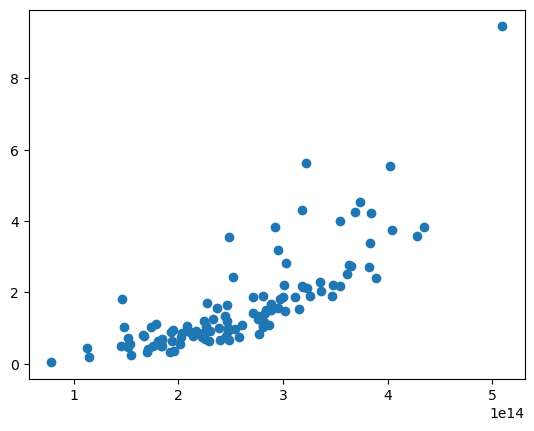

In [10]:
plt.scatter([nfw.M500 for nfw in nfws],[nfw.L500 for nfw in nfws])

In [215]:
test_nfw=nfws[0]

In [219]:
test_nfw.L500_numerical(1e-2, 1e-30)

3.8492487542886824 29.494519361501062 0.754040630613543


(3.8492487542886824, 25.64527060721238)

In [179]:
range(-40, -25)

range(-40, -25)

0.5853001790934521
0.5853001790935195
0.5853001790942017
0.585300179101024
0.5853001791692424
0.5853001798514258
0.5853001866732511
0.5853002548915124
0.5853009370741704
0.5853077589073562
0.5853759778974211
0.586058233624999
0.5928873801536845
0.6618443504262493
1.424594397311215


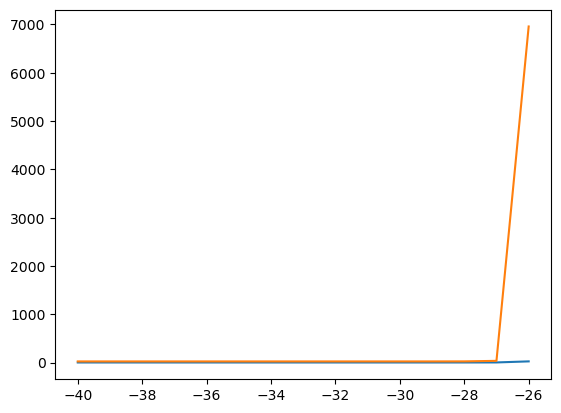

In [182]:
plt.plot([s for s in range(-40, -25)], [test_nfw.L500_numerical(1e-2, 10**s) for s in range(-40, -25)])

In [17]:
test_nfw.L500.value, test_nfw.L_err

(0.846881, 0.136706611275864)

In [249]:
p0=[-27, -2]
obs = [n.L500.value for n in nfws]

In [276]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

print(log_lik(p0, obs, nfws))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

-0.5402881054413954
         104753 function calls in 0.277 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.277    0.139 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    0.277    0.139 {built-in method builtins.exec}
        1    0.000    0.000    0.277    0.277 /var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_54167/1602214845.py:1(<module>)
        1    0.002    0.002    0.276    0.276 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:22(log_lik)
        1    0.000    0.000    0.249    0.249 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:51(<listcomp>)
      111    0.015    0.000    0.249    0.002 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:445(L500_numerical)
      333    0.001    0.000    0.231    0.001 /Users

In [224]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)

Text(0, 0.5, 'net heating rate (erg/s)')

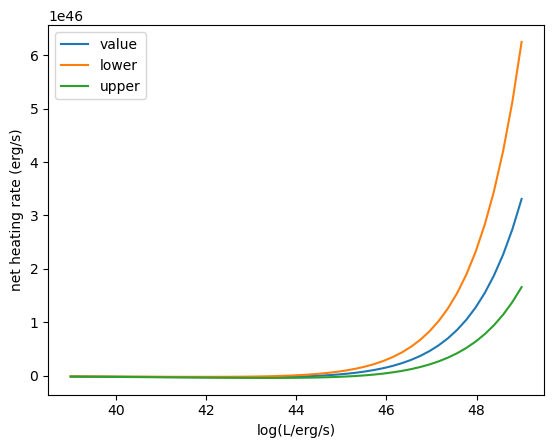

In [230]:
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')
#

Text(0, 0.5, 'net heating rate (erg/s)')

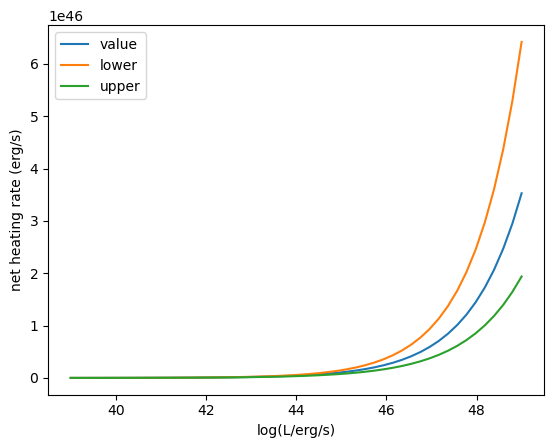

In [232]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

Text(0, 0.5, 'net heating rate (erg/s)')

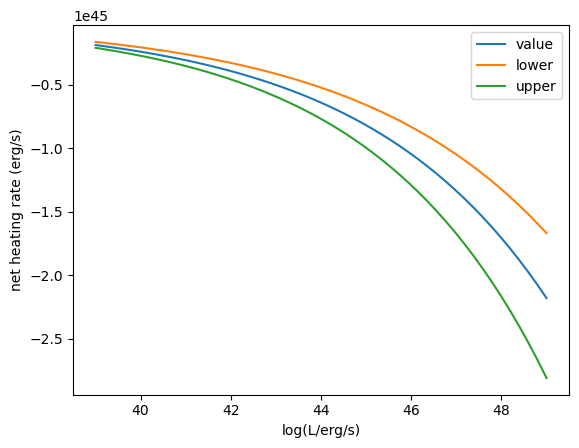

In [234]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

In [235]:
from cluster_error_prop import Linj_from_L500

Text(0, 0.5, 'logLinj (erg/s)')

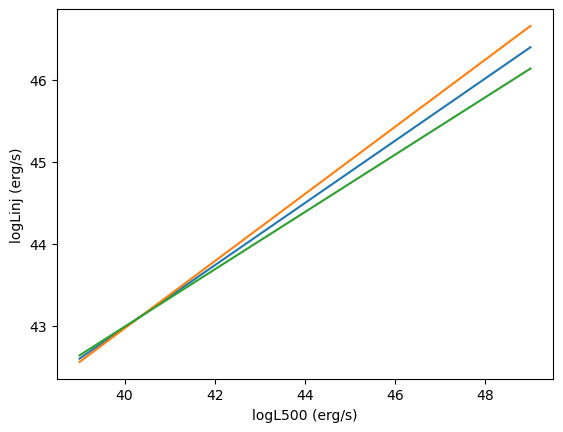

In [242]:
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5))))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='max')))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='min')))
plt.xlabel('logL500 (erg/s)')
plt.ylabel('logLinj (erg/s)')
#plt.yscale('log')

In [300]:
import numpy as np

# Create linearly spaced values from -40 to -30
s0_linear = np.linspace(-40, -29, 5)

# Create exponentially spaced values from -30 to -25
s0_exponential = -28 + np.geomspace(1, 3, 10) - 1

# Combine the arrays
s0_combined = np.concatenate((s0_linear, s0_exponential))

# Create the list of p0
p0_list = [[s0, -2] for s0 in s0_combined]

print(p0_list)

[[-40.0, -2], [-37.25, -2], [-34.5, -2], [-31.75, -2], [-29.0, -2], [-28.0, -2], [-27.870169036090246, -2], [-27.72348199299076, -2], [-27.557750429692593, -2], [-27.370501777781154, -2], [-27.15894245290125, -2], [-26.919916176948096, -2], [-26.649856889188182, -2], [-26.344735543785617, -2], [-26.0, -2]]


In [301]:
s0_combined

array([-40.        , -37.25      , -34.5       , -31.75      ,
       -29.        , -28.        , -27.87016904, -27.72348199,
       -27.55775043, -27.37050178, -27.15894245, -26.91991618,
       -26.64985689, -26.34473554, -26.        ])

In [302]:
s0_combined

array([-40.        , -37.25      , -34.5       , -31.75      ,
       -29.        , -28.        , -27.87016904, -27.72348199,
       -27.55775043, -27.37050178, -27.15894245, -26.91991618,
       -26.64985689, -26.34473554, -26.        ])

In [328]:
log_liks = [log_lik(p, obs, nfws) for p in p0_list]
log_liks

[-163680.8948300916,
 -163680.89483495013,
 -163680.8975670759,
 -163682.4337302772,
 -164474.6901449388,
 -164966.51144826246,
 -162201.27362609544,
 -155543.2397783203,
 -141330.36205073204,
 -115713.62178143127,
 -79652.58687604684,
 -42938.68786784393,
 -17306.27575287417,
 -4942.26307450125,
 -898.313034616919]

Text(0.5, 1.0, 'log likelihood without variance on scaling relations')

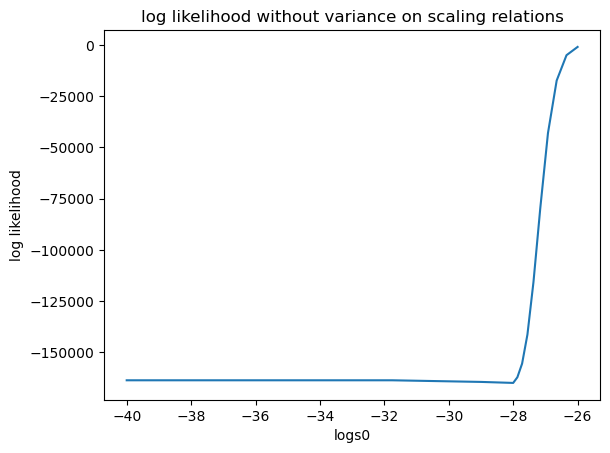

In [329]:
plt.plot(s0_combined, log_liks)
plt.xlabel('logs0')
plt.ylabel('log likelihood')

plt.title('log likelihood without variance on scaling relations')

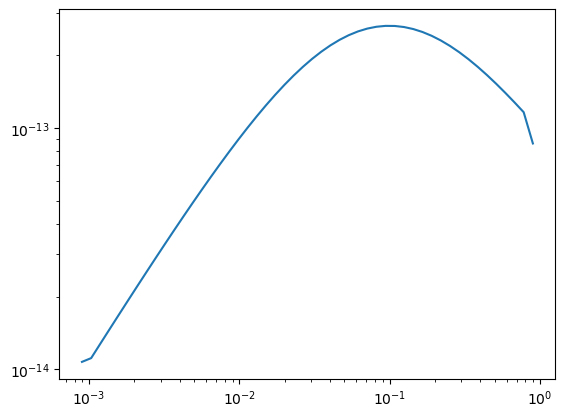

In [210]:
test_nfw.agn_factors.value

1.4046160355643502

In [211]:
test_nfw.rad_factors.value

1.0644290395990223e+41

In [212]:
test_nfw.precalc.rad_factors_min